# Improved GNN Face Emotion Recognition

This notebook implements an enhanced version of the GNN face emotion recognition model with:
- Deeper GAT-based architecture with residual connections
- Advanced data augmentation and landmark normalization
- Multi-head attention fusion
- Learning rate scheduling and comprehensive regularization
- Target accuracy: ~90%


In [1]:
import os
import cv2
import glob
import numpy as np
import pandas as pd
import torch

from torch_geometric.data.data import (
    Data,
    DataEdgeAttr,
    DataTensorAttr
)

torch.serialization.add_safe_globals([
    Data,
    DataEdgeAttr,
    DataTensorAttr
])


import torch.nn as nn
print(nn)
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torch_geometric.data import Data, Batch
from torch_geometric.nn import GATConv, global_mean_pool, global_max_pool
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import warnings
from collections import Counter
warnings.filterwarnings("ignore")

import torch
from torch_geometric.data.data import Data, DataEdgeAttr

torch.serialization.add_safe_globals([Data, DataEdgeAttr])

# Modern MediaPipe Tasks API
from mediapipe.tasks.python import vision
from mediapipe.tasks.python.vision import FaceLandmarker, FaceLandmarkerOptions, RunningMode
from mediapipe.tasks.python import BaseOptions  # CORRECT IMPORT
import mediapipe as mp  # for mp.Image

# GPU setup with AMP
from torch.amp import autocast, GradScaler

<module 'torch.nn' from 'f:\\python\\Lib\\site-packages\\torch\\nn\\__init__.py'>


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    print("cuDNN benchmark enabled for better performance")

scaler = GradScaler('cuda' if torch.cuda.is_available() else 'cpu')

Using device: cuda
cuDNN benchmark enabled for better performance


In [3]:
# Configuration
IMG_SIZE = 128
BATCH_SIZE = 48
NUM_WORKERS = 4  # 0 for Windows (avoids pickle error) — change to 4 later if needed
K_NEIGHBORS = 6
subset_fraction = 1.0  # 10% for fast test — change to 1.0 for full

# Paths to all datasets
AFFECTNET_DIR = r"C:\Users\jahud\###RESEARCH###\Affectnet"
FERPLUS_DIR = r"C:\Users\jahud\###RESEARCH###\FER+"
FACIAL_EMOTION_RECOGNITION_DIR = r"C:\Users\jahud\###RESEARCH###\Facial Emotion Recognition"
MMA_DIR = r"C:\Users\jahud\###RESEARCH###\MMA FACIAL EXPRESSION"

#root_dirs = [AFFECTNET_DIR]
#root_dirs = [FERPLUS_DIR]
#root_dirs = [FACIAL_EMOTION_RECOGNITION_DIR]
#root_dirs = [MMA  FACIAL EXPRESSION_DIR]


DATASET_NAME = "Facial Emotion Recognition"  
# OPTIONS: "AffectNet", "FER+", "FACIAL_EMOTION_RECOGNITION", "MMA"


if DATASET_NAME == "AffectNet":
    root_dirs = [AFFECTNET_DIR]
elif DATASET_NAME == "FER+":
    root_dirs = [FERPLUS_DIR]
elif DATASET_NAME == "Facial Emotion Recognition":
    root_dirs = [FACIAL_EMOTION_RECOGNITION_DIR]
elif DATASET_NAME == "MMA FACIAL EXPRESSION":
    root_dirs = [MMA_DIR]
else:
    raise ValueError("Unknown DATASET_NAME")



# Landmark subset
LANDMARK_SUBSET_INDICES = [
    234, 93, 132, 58, 172, 136, 150, 149, 176, 148, 152, 377, 400, 378, 379, 365, 397, 288, 361, 323, 454,
    70, 63, 105, 66, 107, 336, 296, 334, 293, 300,
    168, 6, 197, 195, 5,
    48, 115, 220, 45, 4, 275, 440, 344, 278,
    33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7,
    362, 398, 384, 385, 386, 387, 388, 466, 263, 249, 390, 373, 374, 380, 381, 382,
    0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 61, 185, 40, 39, 37
]

os.makedirs('models', exist_ok=True)
os.makedirs('results', exist_ok=True)

In [4]:
def collate_fn(batch):
    images, graphs, labels = zip(*batch)
    images = torch.stack(images)
    labels = torch.tensor(labels, dtype=torch.long)
    graphs = Batch.from_data_list(graphs)
    return images, graphs, labels

In [5]:
import os
import glob
import cv2
import torch
import numpy as np
from torch.utils.data import Dataset
from collections import Counter
from PIL import Image
from sklearn.neighbors import NearestNeighbors
from torch_geometric.data import Data
from torchvision import transforms
import mediapipe as mp
from mediapipe.tasks.python import vision
from mediapipe.tasks.python import BaseOptions
from mediapipe.tasks.python.vision import (
    FaceLandmarker,
    FaceLandmarkerOptions,
    RunningMode
)




class ImprovedFaceGraphDataset(Dataset):
    def __init__(
        self,
        root_dirs,
        split = "train",
        subset_indices=None,
        transform=None,
        k_neighbors=10,
        subset_fraction=1.0,
        augment_landmarks=False,
        cache_dir="graph_cache"
    ):
        self.split = split
        self.root_dirs = root_dirs
        self.transform = transform
        self.subset_indices = subset_indices
        self.k_neighbors = k_neighbors
        self.augment_landmarks = augment_landmarks
        self.cache_dir = cache_dir
        os.makedirs(cache_dir, exist_ok=True)

        # -------------------------
        # MediaPipe Face Landmarker
        # -------------------------
        base_options = BaseOptions(
            model_asset_path=r"C:\Users\jahud\###RESEARCH###\models\face_landmarker.task"
        )

        options = FaceLandmarkerOptions(
            base_options=base_options,
            running_mode=RunningMode.IMAGE,
            num_faces=1,
            min_face_detection_confidence=0.35,
            min_face_presence_confidence=0.35,
            min_tracking_confidence=0.35,
            output_face_blendshapes=False,
            output_facial_transformation_matrixes=False
        )

        self.face_landmarker = FaceLandmarker.create_from_options(options)

        # -------------------------
        # Detect dataset & classes
        # -------------------------
        root_name = root_dirs[0].lower()

        if "affectnet" in root_name:
            self.class_names = [
                "anger", "contempt", "disgust", "fear",
                "happy", "neutral", "sad", "surprise"
            ]

        elif "fer+" in root_name or "fer" in root_name:
            self.class_names = [
                "anger", "contempt", "disgust", "fear",
                "happy", "neutral", "sad", "surprise"
            ]

        elif "facial emotion recognition" in root_name:
            self.class_names = [
                "anger", "happy", "neutral",
                "sad", "surprise", "ahegao"
            ]

        elif "mma facial expression" in root_name:
            self.class_names = [
                "anger", "disgust", "fear",
                "happy", "neutral", "sad", "surprise"
            ]

        else:
            raise ValueError(f"Unknown dataset structure: {root_dirs[0]}")

        self.class_map = {c: i for i, c in enumerate(self.class_names)}

        # -------------------------
        # Scan files
        # -------------------------
        self.files = []

        for root_dir in root_dirs:
            for cls in self.class_names:

                # Folder name mapping
                # Folder name mapping (dataset-specific)

                cls_dir = cls
                root_lower = root_dir.lower()

                if "facial emotion recognition" in root_lower:
                    mapping = {
                        "anger": "Angry",
                        "happy": "Happy",
                        "neutral": "Neutral",
                        "sad": "Sad",
                        "surprise": "Surprise",
                        "ahegao": "Ahegao"
                    }
                    cls_dir = mapping.get(cls, cls)

                elif "fer+" in root_lower or "mma facial expression" in root_lower:
                    if cls == "anger":
                        cls_dir = "angry"
                    else:
                        cls_dir = cls

                # AffectNet needs NO change (already lowercase)

                # -------- Build class path --------
                if "facial emotion recognition" in root_lower:
                    cls_path = os.path.join(root_dir, cls_dir)

                elif "mma facial expression" in root_lower:
                    # MMA uses 'valid' instead of 'validation'
                    split_folder = "valid" if self.split == "validation" else self.split
                    cls_path = os.path.join(root_dir, split_folder, cls_dir)

                else:
                    cls_path = os.path.join(root_dir, self.split, cls_dir)
                # -------- Collect images --------
                
                if os.path.isdir(cls_path):
                    imgs = (
                        glob.glob(os.path.join(cls_path, "*.jpg")) +
                        glob.glob(os.path.join(cls_path, "*.png"))
                    )
                    for img in imgs:
                        self.files.append((img, self.class_map[cls]))
                          

        if subset_fraction < 1.0:
            import random
            random.seed(42)
            self.files = random.sample(
                self.files, int(len(self.files) * subset_fraction)
            )

        # -------------------------
        # Dataset stats
        # -------------------------
        print("Classes found:", self.class_names)
        print("Total images:", len(self.files))
        print("Class distribution:", Counter([y for _, y in self.files]))

    # -------------------------
    # Landmark extraction
    # -------------------------
    def _get_landmarks(self, image):
        if image.shape[0] < 80 or image.shape[1] < 80:
            image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))

        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=image_rgb
        )

        results = self.face_landmarker.detect(mp_image)
        if not results.face_landmarks:
            return None

        landmarks = np.array(
            [[lm.x, lm.y, lm.z] for lm in results.face_landmarks[0]]
        )

        if self.subset_indices is not None:
            landmarks = landmarks[self.subset_indices]

        if self.augment_landmarks:
            landmarks += np.random.normal(0, 0.005, landmarks.shape)

        return landmarks

    # -------------------------
    # Dataset interface
    # -------------------------
    def __getitem__(self, idx):
        img_path, label = self.files[idx]

        image = cv2.imread(img_path)
        if image is None:
            return self.__getitem__((idx + 1) % len(self))

        landmarks = self._get_landmarks(image)
        if landmarks is None:
            return self.__getitem__((idx + 1) % len(self))

        nn = NearestNeighbors(n_neighbors=self.k_neighbors + 1)
        nn.fit(landmarks)
        _, idxs = nn.kneighbors(landmarks)

        src, dst = [], []
        for i in range(len(landmarks)):
            for j in range(1, self.k_neighbors + 1):
                src.append(i)
                dst.append(int(idxs[i, j]))

        edge_index = torch.tensor([src, dst], dtype=torch.long)

        graph = Data(
        x=torch.tensor(landmarks, dtype=torch.float),
        edge_index=edge_index,
        y=torch.tensor([label], dtype=torch.long)
        )

        if self.transform:
            image = self.transform(
                Image.fromarray(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
            )

        return image, graph, label

    def __len__(self):
        return len(self.files)


In [6]:
# Training transforms
transforms_train = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.RandomAffine(degrees=5, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation transforms
transforms_val = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create dataset
full_dataset = ImprovedFaceGraphDataset(
    root_dirs=root_dirs,
    split= "train", 
    subset_indices=LANDMARK_SUBSET_INDICES,
    transform=transforms_train,
    k_neighbors=K_NEIGHBORS,
    augment_landmarks=True,
    subset_fraction=1.0,
    cache_dir=f"graph_cache_train_{DATASET_NAME}"
)




Classes found: ['anger', 'happy', 'neutral', 'sad', 'surprise', 'ahegao']
Total images: 15232
Class distribution: Counter({2: 3945, 3: 3875, 1: 3673, 0: 1303, 4: 1231, 5: 1205})


In [7]:
# ================= TRAIN / VAL / TEST SPLIT =================

from torch.utils.data import Subset
import numpy as np

dataset_size = len(full_dataset)
indices = np.arange(dataset_size)

np.random.seed(42)
np.random.shuffle(indices)

# 20% test
test_size = int(0.2 * dataset_size)
test_indices = indices[:test_size]

# remaining 80%
trainval_indices = indices[test_size:]

# split remaining 80% -> 80% train, 20% val
val_size = int(0.2 * len(trainval_indices))
val_indices = trainval_indices[:val_size]
train_indices = trainval_indices[val_size:]

train_dataset = Subset(full_dataset, train_indices)
val_dataset   = Subset(full_dataset, val_indices)
test_dataset  = Subset(full_dataset, test_indices)

# assign transforms correctly
train_dataset.dataset.transform = transforms_train
val_dataset.dataset.transform   = transforms_val
test_dataset.dataset.transform  = transforms_val

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True
)

# Summary
print(f"\n{'='*70}")
print(f"DATASET READY: {DATASET_NAME}")
print(f"  Total samples (subset): {len(full_dataset)}")
print(f"  Train samples: {len(train_dataset)}")
print(f"  Val samples: {len(val_dataset)}")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Num workers: 0")
print(f"  Classes: {full_dataset.class_names}")
print("="*70)



DATASET READY: Facial Emotion Recognition
  Total samples (subset): 15232
  Train samples: 9749
  Val samples: 2437
  Batch size: 48
  Num workers: 0
  Classes: ['anger', 'happy', 'neutral', 'sad', 'surprise', 'ahegao']


In [8]:
# ========================================================
# MODEL DEFINITION — ImprovedFaceGNN (73% VERSION)
# ========================================================

class ImprovedFaceGNN(nn.Module):
    def __init__(
        self,
        num_node_features=3,
        hidden_channels=48,
        num_heads=1,
        num_classes=None
    ):
        super().__init__()
        assert num_classes is not None

        # =============== CNN BACKBONE =================
        resnet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

        self.cnn = nn.Sequential(
            *list(resnet.children())[:-2],
            nn.Conv2d(512, 256, kernel_size=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        # =============== GAT =================
        self.gat1 = GATConv(
            num_node_features,
            hidden_channels,
            heads=num_heads,
            dropout=0.6,
            add_self_loops=False
        )

        self.gat2 = GATConv(
            hidden_channels * num_heads,
            hidden_channels,
            heads=1,
            dropout=0.6,
            add_self_loops=False
        )

        self.dropout = nn.Dropout(0.75)

        # =============== FUSION =================
        self.fusion = nn.Sequential(
            nn.Linear(hidden_channels + 256, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.7),
            nn.Linear(512, num_classes)
        )

    def forward(self, imgs, graphs):
        # CNN branch
        img_feat = self.cnn(imgs).view(imgs.size(0), -1)

        # GNN branch
        x = F.elu(self.gat1(graphs.x, graphs.edge_index))
        x = self.dropout(x)
        x = F.elu(self.gat2(x, graphs.edge_index))
       

        graph_feat = global_mean_pool(x, graphs.batch)

        # Fusion
        fused = torch.cat([img_feat, graph_feat], dim=1)
        return self.fusion(fused)


print("Model defined: ImprovedFaceGNN (73% baseline, clean split)")


Model defined: ImprovedFaceGNN (73% baseline, clean split)


In [11]:
# ========================================================
# FINAL TRAINING LOOP — OPTIMIZED FOR VAL ACC
# ========================================================

num_classes = len(full_dataset.class_names)
model = ImprovedFaceGNN(num_classes=num_classes).to(device)

# 🔒 Freeze ONLY first ResNet block (layer1)

for name, param in model.cnn.named_parameters():
    if any(k in name for k in ["layer1", "layer2"]):
        param.requires_grad = False

print("ResNet layer1 frozen. Training rest of CNN + GAT + fusion.")




criterion = nn.CrossEntropyLoss(label_smoothing=0.05)



optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=3e-4,               # ↓ lower LR
    weight_decay=5e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.3,
    patience=1, #LR Scheduler patience
    verbose=True
)

best_val_acc = 0.0
best_epoch = 0
patience = 3 #Early stopping patience
num_epochs = 10

for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for imgs, graphs, labels in train_loader:
        imgs, graphs, labels = imgs.to(device), graphs.to(device), labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        with autocast(device_type=device.type):
            outputs = model(imgs, graphs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()
        train_correct += outputs.argmax(1).eq(labels).sum().item()
        train_total += labels.size(0)

    train_acc = 100.0 * train_correct / train_total

    # ---------- Validation ----------
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for imgs, graphs, labels in val_loader:
            imgs, graphs, labels = imgs.to(device), graphs.to(device), labels.to(device)

            with autocast(device_type=device.type):
                outputs = model(imgs, graphs)
                loss = criterion(outputs, labels)

            val_loss += loss.item()
            val_correct += outputs.argmax(1).eq(labels).sum().item()
            val_total += labels.size(0)

    val_acc = 100.0 * val_correct / val_total
    scheduler.step(val_acc)

    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print(f"  Train Acc: {train_acc:.2f}%")
    print(f"  Val   Acc: {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        torch.save(model.state_dict(), "models/best_model_combined_test.pth")
        print("  → Saved new best model")

    if epoch - best_epoch >= patience:
        print("\n⏹ Early stopping triggered")
        break

print(f"\n✅ Training finished. Best Val Acc: {best_val_acc:.2f}%")


ResNet layer1 frozen. Training rest of CNN + GAT + fusion.

Epoch 1/10
  Train Acc: 65.26%
  Val   Acc: 74.03%
  → Saved new best model

Epoch 2/10
  Train Acc: 81.44%
  Val   Acc: 78.09%
  → Saved new best model

Epoch 3/10
  Train Acc: 87.19%
  Val   Acc: 76.86%

Epoch 4/10
  Train Acc: 91.32%
  Val   Acc: 79.57%
  → Saved new best model

Epoch 5/10
  Train Acc: 94.18%
  Val   Acc: 78.01%

Epoch 6/10
  Train Acc: 95.60%
  Val   Acc: 79.15%

Epoch 7/10
  Train Acc: 98.58%
  Val   Acc: 83.26%
  → Saved new best model

Epoch 8/10
  Train Acc: 99.65%
  Val   Acc: 82.81%

Epoch 9/10
  Train Acc: 99.81%
  Val   Acc: 82.64%

Epoch 10/10
  Train Acc: 99.83%
  Val   Acc: 82.48%

⏹ Early stopping triggered

✅ Training finished. Best Val Acc: 83.26%


In [25]:
model = ImprovedFaceGNN(num_classes=len(full_dataset.class_names)).to(device)
model.load_state_dict(torch.load("models/best_model_combined_test.pth", map_location=device))

# 🔒 Freeze same layers again
for name, param in model.cnn.named_parameters():
    if any(k in name for k in ["layer1", "layer2"]):
        param.requires_grad = False

model.eval()


ImprovedFaceGNN(
  (cnn): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=T

In [16]:
print("Test samples:", len(test_loader.dataset))

acc, prec, rec, f1, cm = evaluate_model(
    model,
    test_loader,
    full_dataset.class_names

)

acc, prec, rec, weighted_f1, macro_f1, cm = evaluate_model(
    model,
    test_loader,
    full_dataset.class_names
)

print(f"\n{DATASET_NAME} Results:")
print(f"Accuracy   : {acc*100:.2f}%")
print(f"Precision  : {prec*100:.2f}%")
print(f"Recall     : {rec*100:.2f}%")
print(f"Weighted F1: {weighted_f1*100:.2f}%")



Test samples: 3046

Classification Report:
              precision    recall  f1-score   support

       anger       0.82      0.74      0.78       259
       happy       0.92      0.94      0.93       756
     neutral       0.75      0.79      0.77       815
         sad       0.78      0.76      0.77       777
    surprise       0.88      0.78      0.82       220
      ahegao       0.97      0.99      0.98       219

    accuracy                           0.83      3046
   macro avg       0.85      0.83      0.84      3046
weighted avg       0.83      0.83      0.83      3046


Classification Report:
              precision    recall  f1-score   support

       anger       0.82      0.74      0.78       259
       happy       0.92      0.94      0.93       756
     neutral       0.75      0.79      0.77       815
         sad       0.78      0.76      0.77       777
    surprise       0.88      0.78      0.82       220
      ahegao       0.97      0.99      0.98       219

    accura

ValueError: not enough values to unpack (expected 6, got 5)

In [14]:
results = {
    "Dataset": DATASET_NAME,
    "Test Accuracy": acc * 100,
    "Weighted F1": f1 * 100,
    "Macro F1": f1_score,  # if stored separately
}

print(results)


{'Dataset': 'Facial Emotion Recognition', 'Test Accuracy': 82.9940906106369, 'Weighted F1': 82.95990333356522, 'Macro F1': <function f1_score at 0x000002D98A01D080>}


In [19]:
#split="test"


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

def evaluate_model(model, test_loader, class_names):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for imgs, graphs, labels in test_loader:
            imgs = imgs.to(device)
            graphs = graphs.to(device)
            labels = labels.to(device)

            outputs = model(imgs, graphs)
            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    labels_range = list(range(len(class_names)))

    acc = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, average="weighted", zero_division=0)
    rec = recall_score(all_labels, all_preds, average="weighted", zero_division=0)
    f1 = f1_score(all_labels, all_preds, average="weighted", zero_division=0)
    cm = confusion_matrix(all_labels, all_preds, labels=labels_range)
    macro_f1 = f1_score(all_labels, all_preds, average="macro", zero_division=0)

    print("\nClassification Report:")
    print(classification_report(
        all_labels,
        all_preds,
        labels=labels_range,
        target_names=class_names,
        zero_division=0
    ))

    return acc, prec, rec, f1, macro_f1, cm


In [20]:
print("Test samples:", len(test_loader.dataset))

acc, prec, rec, weighted_f1, macro_f1, cm = evaluate_model(
    model,
    test_loader,
    full_dataset.class_names
)

print(f"\n{DATASET_NAME} Results:")
print(f"Accuracy   : {acc*100:.2f}%")
print(f"Precision  : {prec*100:.2f}%")
print(f"Recall     : {rec*100:.2f}%")
print(f"Weighted F1: {weighted_f1*100:.2f}%")
print(f"Macro F1   : {macro_f1*100:.2f}%")


Test samples: 3046

Classification Report:
              precision    recall  f1-score   support

       anger       0.82      0.74      0.78       259
       happy       0.92      0.94      0.93       756
     neutral       0.75      0.79      0.77       815
         sad       0.78      0.76      0.77       777
    surprise       0.88      0.78      0.82       220
      ahegao       0.97      0.99      0.98       219

    accuracy                           0.83      3046
   macro avg       0.85      0.83      0.84      3046
weighted avg       0.83      0.83      0.83      3046


Facial Emotion Recognition Results:
Accuracy   : 82.99%
Precision  : 83.04%
Recall     : 82.99%
Weighted F1: 82.96%
Macro F1   : 84.22%


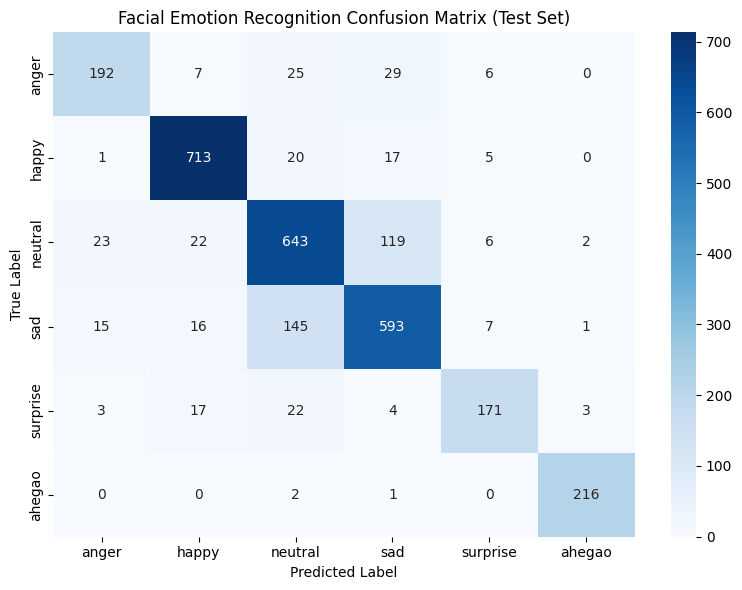

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=full_dataset.class_names,
    yticklabels=full_dataset.class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title(f"{DATASET_NAME} Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()


In [27]:
for name, param in model.named_parameters():
    print(name)
    break


cnn.0.weight


In [28]:
# Freeze ResNet layer1 and layer2 (Sequential index 4 and 5)
for idx in [4, 5]:
    for param in model.cnn[idx].parameters():
        param.requires_grad = False


In [29]:
total_params = sum(p.numel() for p in model.parameters())
print("Total parameters:", total_params)
print("Total parameters (Millions): {:.2f} M".format(total_params / 1e6))



trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable parameters:", trainable_params)
print("Trainable parameters (Millions): {:.2f} M".format(trainable_params / 1e6))



Total parameters: 11471094
Total parameters (Millions): 11.47 M
Trainable parameters: 10797558
Trainable parameters (Millions): 10.80 M


In [14]:
#DATASET_NAME = " "  
# OPTIONS: "AffectNet", "FER+", "MMA FACIAL EXPRESSION", "MMA"
DATASET_NAME = "Facial Emotion Recognition"

if DATASET_NAME == "AffectNet":
    root_dirs = [AFFECTNET_DIR]
elif DATASET_NAME == "FER+":
    root_dirs = [FERPLUS_DIR]
elif DATASET_NAME == "Facial Emotion Recognition":
    root_dirs = [FACIAL_EMOTION_RECOGNITION_DIR]
elif DATASET_NAME == "MMA FACIAL EXPRESSION":
    root_dirs = [MMA_DIR]
else:
    raise ValueError("Unknown DATASET_NAME")

In [17]:
# ================================
#  Evaluation
# ================================


'''#  test dataset
test_dataset = ImprovedFaceGraphDataset(
    root_dirs=root_dirs,
    split="test",
    transform=transforms_val,
    cache_dir="graph_cache_eval_FER+"
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)
'''

# ---------- Load trained model ----------
num_classes = len(test_dataset.class_names)
model = ImprovedFaceGNN(num_classes=num_classes).to(device)
model.load_state_dict(
    torch.load("models/best_model_combined_test.pth", map_location=device)
)
model.eval()

print("✅ Model loaded for evaluation only.")


# ---------- Evaluation ----------
acc, prec, rec, f1, cm = evaluate_model(
    model,
    test_loader,
    test_dataset.class_names
)

print(f"\n{DATASET_NAME} Results:")
print(f"Accuracy : {acc*100:.2f}%")
print(f"Precision: {prec*100:.2f}%")
print(f"Recall   : {rec*100:.2f}%")
print(f"F1-score : {f1*100:.2f}%")


AttributeError: 'Subset' object has no attribute 'class_names'

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

class_names = test_dataset.class_names

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"{DATASET_NAME} Confusion Matrix")
plt.tight_layout()
plt.show()


AttributeError: 'Subset' object has no attribute 'class_names'